# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

In [2]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = Path(r"C:\dev\llm-data-analysis-course")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: c:\Users\82102\Desktop\Ozzang\03 대학원\llm-data-analysis-study\chapter07
프로젝트 루트: C:\dev\llm-data-analysis-course
전처리 데이터 폴더: C:\dev\llm-data-analysis-course\data\processed
그래프 저장 폴더: C:\dev\llm-data-analysis-course\reports\figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [3]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 474
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 0


In [4]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,148990000.0,148990000.0,0.0,True
1,product_completed_amount,148990000.0,148990000.0,0.0,True
2,customer_completed_amount,148990000.0,148990000.0,0.0,True
3,monthly_completed_amount_valid_dates,148990000.0,148990000.0,0.0,True


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: 카테고리별, 상품별, 고객별, 월별 완료 주문 금액이 모두 148,990,000원으로 일치했습니다. 4개 검증 항목의 차이는 모두 0이고, passed는 모두 True였습니다.
- 문제가 있었다면 원인: 집계 총합 검증에서 발견된 문제는 없었습니다. 날짜 결측으로 월별 집계에서 제외된 완료 주문 상세도 0행이었습니다.
- 시각화를 진행해도 된다고 판단한 이유: 완료 주문 기준 금액의 집계 결과가 원본 총합과 일치하여, 동일한 집계 기준으로 그래프를 작성할 수 있다고 판단했습니다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [5]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


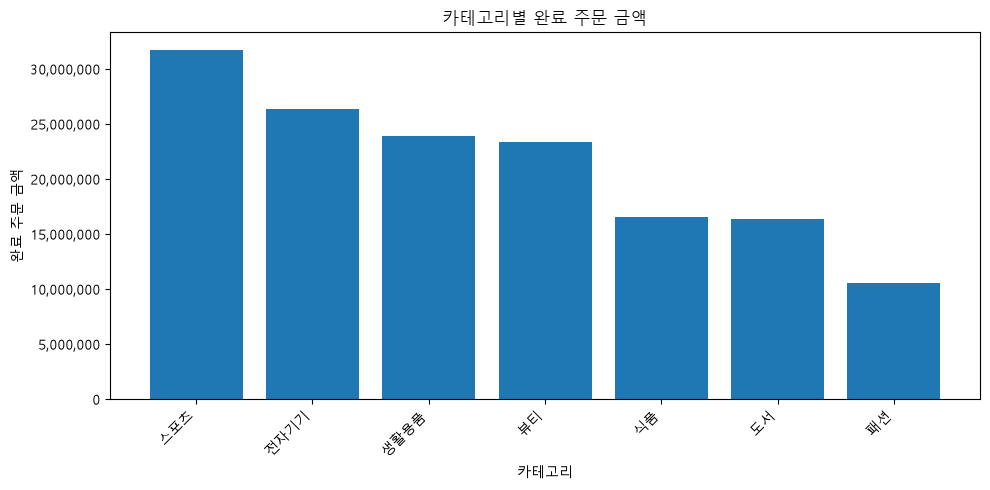

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png')

In [6]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 스포츠가 31,743,000원으로 가장 높고, 패션이 10,587,000원으로 가장 낮았습니다. 생활용품은 전자기기보다 판매 수량이 많지만 완료 주문 금액은 낮았습니다.
- **해석:** 카테고리별로 판매 수량과 완료 주문 금액의 순위가 반드시 일치하지 않는다는 것을 확인했습니다.
- **한계:** 완료 주문 금액만으로 고객 선호도나 수익성을 판단할 수 없습니다.
- **다음 질문:** 카테고리별 평균 판매 단가와 상품 수를 비교하면 금액 차이를 더 잘 설명할 수 있을까?

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [7]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,21085000,23,916739.0
4,2026-01,14272000,16,892000.0
5,2026-02,4784000,7,683429.0
6,2026-03,18323000,25,732920.0
7,2026-04,10254000,15,683600.0
8,2026-05,16831000,19,885842.0
9,2026-06,12994000,17,764353.0


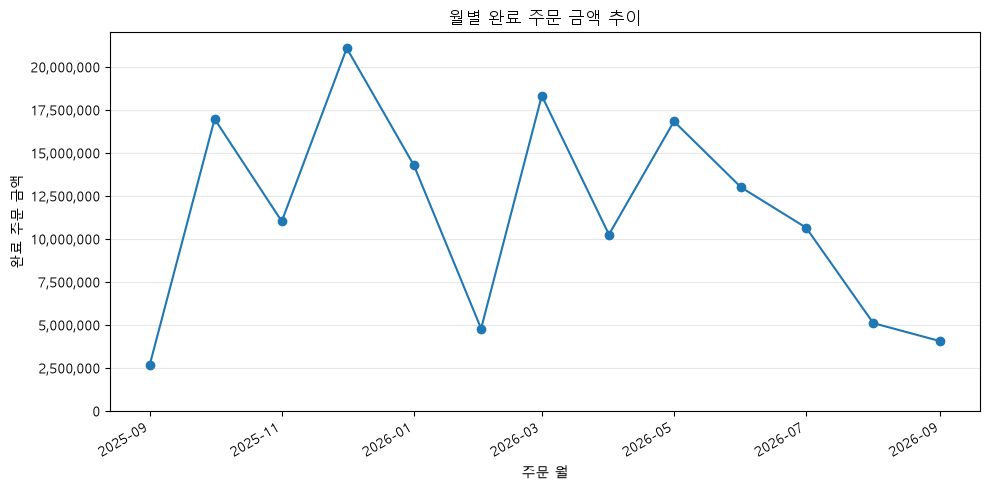

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [8]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

### 그래프 2 기록

- **관찰:** 월별 완료 주문 금액은 증가와 감소를 반복했습니다. 2025년 12월이 21,085,000원으로 가장 높았고, 2025년 9월이 2,650,000원으로 가장 낮았습니다. 완료 주문 건수는 2026년 3월이 25건으로 가장 많았습니다.
- **해석:** 월별 완료 주문 금액과 주문 건수의 최고 시점이 서로 달랐습니다. 주문 금액의 변화는 주문 건수뿐 아니라 주문 1건당 평균 금액과 함께 살펴볼 필요가 있다고 판단했습니다.
- **한계:** 첫 달과 마지막 달은 부분 월이므로 다른 월과 단순 비교하기 어렵습니다. 또한 그래프만으로 계절성이나 프로모션의 영향을 판단할 수 없습니다.
- **다음 질문:** 월별 완료 주문 건수와 평균 주문 금액을 각각 비교하면 금액 변화의 특징을 더 명확하게 설명할 수 있을까요?

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [9]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
Name: price, dtype: float64

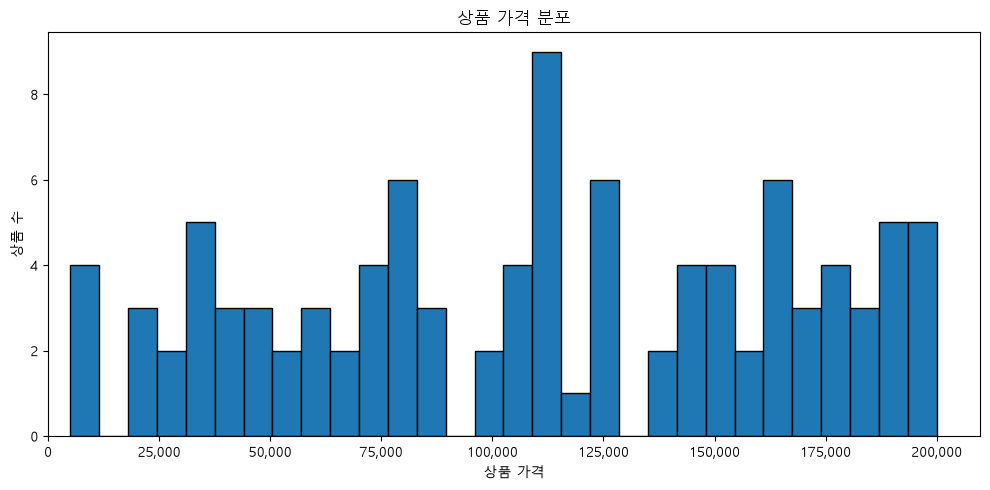

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [12]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=30,
)
price_hist_path

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가? 구간 수를 바꾸어도 상품 가격은 5,000원~200,000원에 분포하며, 10만~12만 원 부근에 상품이 상대적으로 많이 모여 있는 모습이 유지되었습니다.
- 어떤 인상은 bins 선택에 따라 달라지는가? bins=10에서는 전체적인 가격 분포가 비교적 고르게 보였지만, bins=30에서는 특정 가격대에 상품이 집중된 모습이 더 뚜렷하게 나타났습니다. 구간 수에 따라 분포에 대한 인상이 달라질 수 있다는 것을 확인했습니다.

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [13]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
39,163000,35,5705000
11,175000,25,4375000
8,193000,20,3860000
70,189000,20,3780000
69,161000,23,3703000
66,140000,26,3640000
78,165000,22,3630000
10,115000,31,3565000
20,112000,29,3248000
86,103000,30,3090000


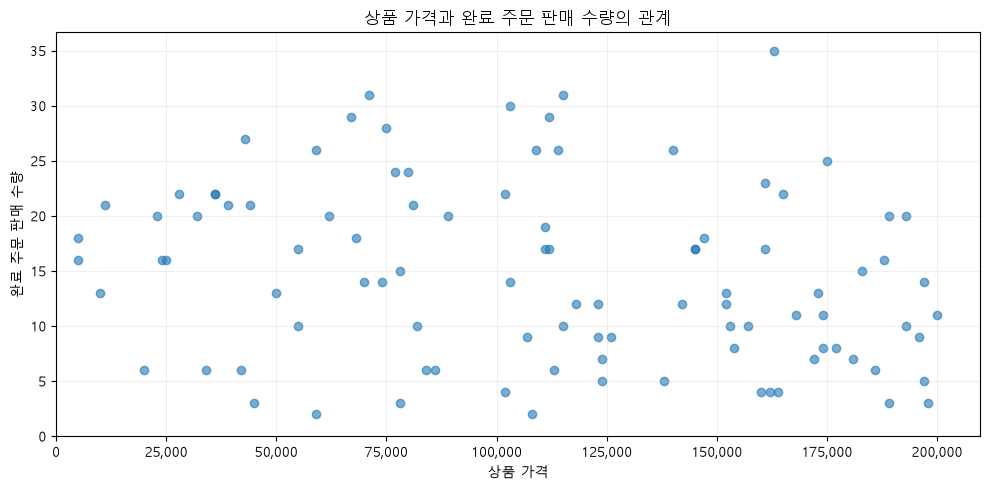

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [14]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 상품 가격은 약 5,000~200,000원, 완료 주문 판매 수량은 약 2~35개 범위에 분포했습니다. 비슷한 가격대에서도 판매 수량에 차이가 있었습니다.
- **해석:** 상품 가격과 판매 수량 사이에 뚜렷한 증가 또는 감소 패턴은 보이지 않았습니다. 가격 외에도 판매 수량과 관련된 다른 요인이 있을 수 있다고 생각했습니다.
- **한계:** 산점도만으로 가격과 판매 수량의 인과관계를 판단할 수 없으며, 상품별 판매 기간이나 재고, 프로모션 등의 영향은 확인하지 못했습니다.
- **다음 질문:** 상품 카테고리별로 나누어 비교하면 가격과 판매 수량 사이에 다른 패턴이 나타날까?

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [15]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
76,117,5,4100000,820000.0
62,102,4,3996000,999000.0
51,83,4,3880000,970000.0
21,30,5,3590000,718000.0
29,40,4,3523000,880750.0
13,20,2,3191000,1595500.0
0,3,2,3178000,1589000.0
70,111,3,3153000,1051000.0
42,66,4,3093000,773250.0
97,147,2,2990000,1495000.0


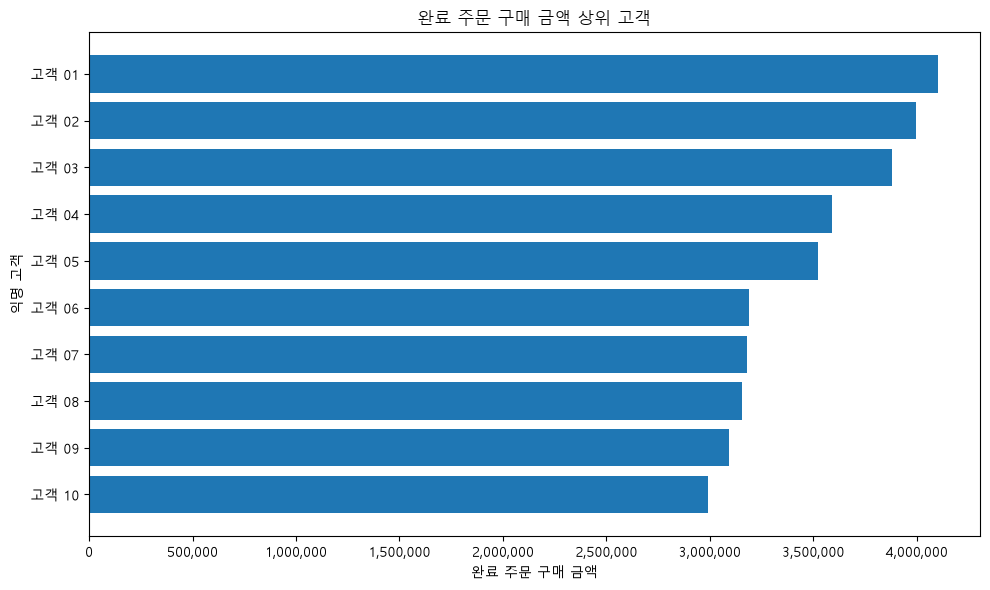

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png')

In [16]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [17]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


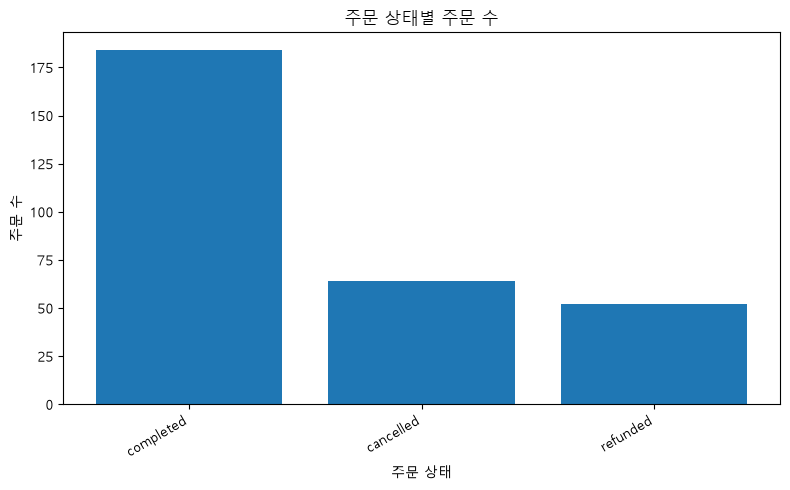

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png')

In [18]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [19]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- C:\dev\llm-data-analysis-course\reports\figures\ch07_category_completed_amount_bar.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_monthly_completed_amount_line.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_product_price_hist.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_price_completed_quantity_scatter.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_top_customers_anonymized_barh.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_order_status_bar.png
요약 보고서: C:\dev\llm-data-analysis-course\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유
월별 완료 주문 금액 선그래프가 가장 중요하다고 생각했습니다. 시간에 따른 금액 변화를 한눈에 볼 수 있고, 월별 주문 건수와 함께 비교할 필요성도 확인할 수 있었기 때문입니다.

### 그래프에서 직접 확인한 사실
2025년 12월의 완료 주문 금액이 21,085,000원으로 가장 높았고, 2025년 9월이 2,650,000원으로 가장 낮았습니다. 반면 완료 주문 건수는 2026년 3월이 25건으로 가장 많았습니다.

### 내가 해석한 내용
완료 주문 금액과 주문 건수가 반드시 같은 흐름을 보이지는 않았습니다. 따라서 월별 실적을 판단할 때 주문 금액뿐 아니라 주문 건수와 평균 주문 금액도 함께 확인해야 한다고 생각했습니다.

### 그래프만으로 말할 수 없는 것
그래프만으로 월별 금액 변화의 원인을 알 수는 없습니다. 특히 데이터 기간이 2025년 9월 16일부터 2026년 9월 15일까지이므로 첫 달과 마지막 달의 금액을 다른 월과 단순 비교하기 어렵습니다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축:금액 축이 0부터 시작하는지 확인했습니다.
- 단위:금액은 원, 주문 건수는 건으로 구분했습니다.
- 정렬:월별 그래프가 시간 순서대로 정렬되어 있는지 확인했습니다.
- 범위:금액 분석은 completed 주문을 기준으로 했고, 첫 달과 마지막 달이 부분 월이라는 점을 확인했습니다
- 개인정보:상위 고객 그래프에서 원본 고객 ID 대신 익명 라벨을 사용한 것을 확인했습니다.

### 다음 분석에서 확인하고 싶은 질문
월별 완료 주문 금액의 변화는 주문 건수와 평균 주문 금액 중 어느 지표의 변화와 더 밀접하게 나타날까요?
---

## 완료 체크

- [X] 질문을 그래프보다 먼저 정했습니다.
- [X] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [X] 집계 검증표의 `passed`를 확인했습니다.
- [X] 대표 그래프 3개 이상을 만들었습니다.
- [X] 그래프와 원본 집계값을 교차 확인했습니다.
- [X] 축·단위·정렬·범위를 확인했습니다.
- [X] 관계를 원인으로 단정하지 않았습니다.
- [X] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [X] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [X] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

> 이 내용을 `chapter07.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: 오현우
- GitHub ID: dhgusdn0312
- 작성일: 2026.10.28
- 최종 Notebook URL: https://github.com/dhgusdn0312/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | 카테고리별 금액의 크기와 순위를 비교하기 좋기 때문입니다. |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | 시간에 따른 금액의 증가와 감소를 확인하기 좋기 때문입니다. |
| 상품 가격과 완료 주문 판매 수량은 어떤 관계가 있는가? | 산점도 | 두 수치형 변수의 분포와 관계를 살펴보기 좋기 때문입니다. |

## 2. 대표 그래프 1

![대표 그래프 1](images/graph01.png)

### 원본 집계값
`completed` 주문 기준 전체 금액은 148,990,000원입니다.

| 카테고리 | 완료 주문 금액 | 비율 |
| --- | ---: | ---: |
| 스포츠 | 31,743,000원 | 21.31% |
| 전자기기 | 26,400,000원 | 17.72% |
| 생활용품 | 23,915,000원 | 16.05% |
| 뷰티 | 23,383,000원 | 15.69% |
| 식품 | 16,573,000원 | 11.12% |
| 도서 | 16,389,000원 | 11.00% |
| 패션 | 10,587,000원 | 7.11% |

카테고리별 금액 합계는 원본 완료 주문 금액과 일치했으며, 검증 결과는 `passed=True`였습니다.

### 결과 관찰
스포츠가 31,743,000원으로 가장 높았고, 패션이 10,587,000원으로 가장 낮았습니다. 그래프는 금액 기준 내림차순으로 정렬되어 있으며 집계표와 일치했습니다.

### 나의 해석과 판단
카테고리별 완료 주문 금액에 차이가 있었습니다. 특히 생활용품은 전자기기보다 판매 수량이 많았지만 금액은 낮아, 판매 수량과 금액의 순위가 반드시 일치하지는 않는다고 판단했습니다.

### 업무·분석적 의미
카테고리별 판매 실적을 평가할 때 금액뿐 아니라 판매 수량과 평균 단가도 함께 비교할 필요가 있습니다.

### 한계와 추가 확인 사항
완료 주문 금액만으로 고객 선호도나 수익성을 판단할 수 없습니다. 카테고리별 상품 수와 평균 판매 단가를 추가로 확인할 필요가 있습니다.

## 3. 대표 그래프 2

![대표 그래프 2](images/graph02.png)

### 원본 집계값
분석 기간은 2025년 9월 16일부터 2026년 9월 15일까지이며, `completed` 주문을 기준으로 집계했습니다.

- 전체 완료 주문 금액: 148,990,000원
- 월별 완료 주문 금액 최고: 2025년 12월, 21,085,000원
- 월별 완료 주문 금액 최저: 2025년 9월, 2,650,000원
- 완료 주문 건수 최고: 2026년 3월, 25건

월별 집계 금액의 합계는 원본 완료 주문 금액과 일치했고, 검증 결과는 `passed=True`였습니다.

### 결과 관찰
월별 완료 주문 금액은 증가와 감소를 반복했습니다. 2025년 12월에 가장 높았으며, 완료 주문 건수가 가장 많은 시점은 2026년 3월로 서로 달랐습니다.

### 나의 해석과 판단
완료 주문 금액이 높은 월이 반드시 주문 건수도 가장 많은 것은 아니었습니다. 따라서 월별 금액 변화를 이해하려면 주문 건수와 평균 주문 금액을 함께 살펴볼 필요가 있다고 판단했습니다.

### 업무·분석적 의미
월별 실적을 비교할 때 완료 주문 금액뿐 아니라 주문 건수와 평균 주문 금액을 함께 확인하면 실적 변화의 특징을 더 구체적으로 파악할 수 있습니다.

### 한계와 추가 확인 사항
첫 달과 마지막 달은 한 달 전체 데이터가 아니므로 다른 월과 직접 비교하기 어렵습니다. 또한 그래프만으로 계절성이나 프로모션이 금액 변화에 영향을 주었는지는 판단할 수 없습니다.

## 4. 대표 그래프 3

![대표 그래프 3](images/graph03.png)

### 원본 집계값
`completed` 주문을 기준으로 상품별 판매 수량을 집계했습니다.

- 상품 가격 범위: 5,000~200,000원
- 그래프에서 관찰한 완료 주문 판매 수량: 약 2~35개
- X축: 상품 가격(원)
- Y축: 완료 주문 판매 수량(개)

상품별 집계 금액의 합계는 원본 완료 주문 금액 148,990,000원과 일치했으며, 검증 결과는 `passed=True`였습니다.

### 결과 관찰
상품 가격이 높아질수록 판매 수량이 일정하게 증가하거나 감소하는 뚜렷한 패턴은 보이지 않았습니다. 비슷한 가격의 상품에서도 판매 수량에 차이가 있었습니다.

### 나의 해석과 판단
가격과 판매 수량 사이의 관계가 뚜렷하지 않아, 가격만으로 판매 수량을 설명하기는 어렵다고 판단했습니다. 다른 요인도 함께 살펴볼 필요가 있다고 생각했습니다.

### 업무·분석적 의미
상품별 판매 특성을 분석할 때 가격과 판매 수량뿐 아니라 카테고리와 판매 기간 등 다른 조건도 함께 비교할 필요가 있습니다.

### 한계와 추가 확인 사항
산점도에서 보이는 관계만으로 인과관계를 판단할 수 없습니다. 상품별 재고, 프로모션, 노출 기간 등의 정보가 없어 이러한 요인의 영향은 확인하지 못했습니다.

## 5. 그래프 정확성 점검

- [x] 그래프 값과 집계표 값 일치
- [x] 축 이름 확인
- [x] 단위 확인
- [x] 범례 확인
- [x] 날짜 정렬 확인
- [x] 과장될 수 있는 축 범위 확인
- [x] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
월별 완료 주문 금액 선그래프에서 첫 달과 마지막 달은 전체 한 달이 아닌 일부 기간만 포함하고 있습니다. 이를 고려하지 않으면 해당 월의 금액이 다른 월보다 적다고 잘못 해석할 수 있습니다.
따라서 분석 기간이 2025년 9월 16일부터 2026년 9월 15일까지라는 점을 확인하고, 부분 월은 다른 월과 직접 비교하기 어렵다는 내용을 해석에 반영했습니다.
또한 카테고리별 막대그래프는 금액 축이 0부터 시작하는지 확인해 차이가 과장되지 않도록 점검했습니다.

## 6. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유
월별 완료 주문 금액 선그래프가 가장 중요하다고 생각했습니다. 시간에 따른 금액 변화를 한눈에 볼 수 있고, 월별 주문 건수와 함께 비교할 필요성도 확인할 수 있었기 때문입니다.

### 그래프가 보여 준 사실
2025년 12월의 완료 주문 금액이 21,085,000원으로 가장 높았고, 2025년 9월이 2,650,000원으로 가장 낮았습니다. 반면 완료 주문 건수는 2026년 3월이 25건으로 가장 많았습니다.

### 그래프만으로 말할 수 없는 것
월별 금액 변화의 원인을 그래프만으로 판단할 수 없습니다. 특히 첫 달과 마지막 달은 일부 기간만 포함하므로 다른 월과 단순 비교하기 어렵습니다. 계절성이나 프로모션의 영향도 현재 데이터만으로는 확인할 수 없습니다.

### 다음 분석에서 확인할 질문
월별 완료 주문 금액의 변화는 주문 건수와 평균 주문 금액 중 어느 지표의 변화와 더 밀접하게 나타날까요?

## 최종 체크
- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.